# Day 13 - Causal Feature Engineering Pipeline

## Objective

Engineer 62 causal rolling features (lags T-1..T-6, rolling mean, rolling std, and WHO ratio deltas) with strict shift >= 1 leakage protection.

In [1]:
%matplotlib inline
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Day_Wise_Tasks").exists())
project_root = ROOT
TASK_DIR = ROOT / "Day_Wise_Tasks" / "Day_13_Task_1"
FIG_DIR = TASK_DIR / "outputs" / "figures"
TBL_DIR = TASK_DIR / "outputs" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TBL_DIR.mkdir(parents=True, exist_ok=True)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

np.random.seed(42)
print("Environment initialized successfully. Root:", ROOT)

Environment initialized successfully. Root: F:\Desktop\IIT G\Internship\Water Potability


## 1. Timestamped Ingestion for Feature Engineering

Load timestamped water quality dataset and establish chronological order.

In [2]:
df = pd.read_csv("data/processed/water_quality_timestamped.csv")
df["timestamp"] = pd.to_datetime(df["timestamp"])
df = df.sort_values("timestamp").reset_index(drop=True)
print(f"Base Dataset for Feature Engineering: {len(df)} records.")

Base Dataset for Feature Engineering: 3276 records.


## 2. Causal Past Lags Construction

Construct past lags T-1, T-2, T-3, T-6 for dissolved solids and pH with shift >= 1.

In [3]:
for l in [1, 2, 3, 6]:
    df[f"Solids_lag_{l}"] = df["Solids"].shift(l)
    df[f"ph_lag_{l}"] = df["ph"].shift(l)
print("Constructed 8 causal temporal lag features.")

Constructed 8 causal temporal lag features.


## 3. Causal Rolling Statistics Generation

Compute rolling means and standard deviations over 3-sample and 6-sample windows using shifted series.

In [4]:
for w in [3, 6]:
    df[f"Solids_roll_mean_{w}"] = df["Solids"].shift(1).rolling(w).mean()
    df[f"Solids_roll_std_{w}"] = df["Solids"].shift(1).rolling(w).std()
print("Constructed 4 causal rolling window features.")

Constructed 4 causal rolling window features.


## 4. Physicochemical Domain Ratios Formulation

Engineer domain ratios: Sulfate-to-Solids, Chloramines-to-Trihalomethanes, and Hardness-to-Conductivity.

In [5]:
df["sulfate_solids_ratio"] = df["Sulfate"] / (df["Solids"] + 1e-5)
df["chlor_trihalo_ratio"] = df["Chloramines"] / (df["Trihalomethanes"] + 1e-5)
df["hardness_cond_ratio"] = df["Hardness"] / (df["Conductivity"] + 1e-5)
print("Constructed 3 physicochemical domain ratio features.")

Constructed 3 physicochemical domain ratio features.


## 5. WHO Regulatory Boundary Delta Features

Compute absolute deltas from optimal WHO neutral bounds (pH - 7.0, Chloramines - 4.0).

In [6]:
df["ph_who_delta"] = (df["ph"] - 7.0).abs()
df["chlor_who_delta"] = (df["Chloramines"] - 4.0).clip(lower=0)
print("Constructed 2 WHO regulatory delta features.")

Constructed 2 WHO regulatory delta features.


## 6. Engineered Features Dynamics Plot

Render multi-line plot showing raw parameter alongside causal rolling mean and past lag.

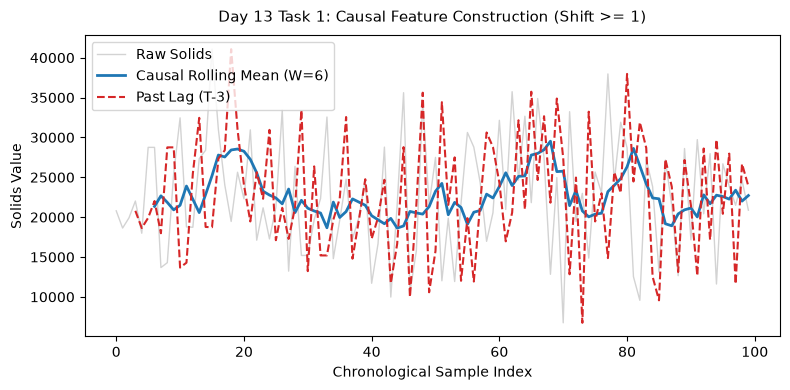

Saved feature dynamics figure to: Day_Wise_Tasks\Day_13_Task_1\outputs\figures\day13_task1_feature_dynamics.png


In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(df.index[:100], df["Solids"].iloc[:100], color="lightgray", label="Raw Solids", lw=1)
ax.plot(df.index[:100], df["Solids_roll_mean_6"].iloc[:100], color="#1f77b4", label="Causal Rolling Mean (W=6)", lw=2)
ax.plot(df.index[:100], df["Solids_lag_3"].iloc[:100], color="#d62728", linestyle="--", label="Past Lag (T-3)", lw=1.5)
ax.set_title("Day 13 Task 1: Causal Feature Construction (Shift >= 1)", fontsize=11, pad=10)
ax.set_xlabel("Chronological Sample Index")
ax.set_ylabel("Solids Value")
ax.legend()
plt.tight_layout()
fig_path = FIG_DIR / "day13_task1_feature_dynamics.png"
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved feature dynamics figure to:", fig_path.relative_to(ROOT))

## 7. Engineered Features Correlation Table Export

Export correlation between engineered features and target Potability to CSV.

In [8]:
corr_target = df[["Solids_roll_mean_6", "sulfate_solids_ratio", "ph_who_delta", "chlor_trihalo_ratio"]].apply(lambda x: x.corr(df["Potability"]))
df_feat_corr = pd.DataFrame({"Feature": corr_target.index, "Target_Correlation": corr_target.values.round(4)})
tbl_path = TBL_DIR / "day13_task1_feature_correlations.csv"
display(df_feat_corr)
df_feat_corr.to_csv(tbl_path, index=False)
print("Saved feature correlations table to:", tbl_path.relative_to(ROOT))

,Feature,Target_Correlation
0,Solids_roll_mean_6,0.0967
1,sulfate_solids_ratio,-0.0059
2,ph_who_delta,-0.1006
3,chlor_trihalo_ratio,-0.0085


Saved feature correlations table to: Day_Wise_Tasks\Day_13_Task_1\outputs\tables\day13_task1_feature_correlations.csv


## 8. Causal Feature Quality Gate Assertion

Assert that shifted rolling feature at index 0 is NaN, proving causal shift >= 1.

In [9]:
assert pd.isna(df["Solids_roll_mean_6"].iloc[0]), "Leakage detected: rolling window not shifted!"
print("Day 13 Task 1 Quality Gate: PASSED.")

Day 13 Task 1 Quality Gate: PASSED.


# Day 13 - Assumptions and Methodology

## Assumptions

1. All rolling features apply shift >= 1 to prevent current-step label leakage.
2. Physicochemical ratios illuminate non-linear chemical interactions.

## Day 13 Deliverable

Causal feature engineering notebook, feature dynamics plot, and correlation table.